<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/statistical_physics/statphys_ch05_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Statistical Physics* — `statphys_ch05_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Statistical Physics — Chapter 5 Figures

Run in Google Colab. All figures saved to `figures/`.

| File | Slide |
|---|---|
| `fig_vdw_isotherms.png` | §5.1 (van der Waals isotherms) |
| `fig_maxwell_construction.png` | §5.1.1 (Maxwell equal-area rule) |
| `fig_mft_selfconsistency.png` | §5.2.1 (mean field graphical solution) |
| `fig_mft_magnetisation.png` | §5.2.1 (magnetisation m(T) at B=0 and B≠0) |
| `fig_landau_second_order.png` | §5.4.1 (Landau free energy, second order) |
| `fig_landau_first_order.png` | §5.4.2 (Landau free energy, first order) |
| `fig_lee_yang.png` | §5.4.3 (Lee-Yang zeros in complex z-plane) |
| `fig_domain_wall.png` | §5.5 (domain wall profile) |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch
from scipy.optimize import fsolve
import os

os.makedirs('figures', exist_ok=True)

DARK_BG  = '#1a1a2e'
PANEL_BG = '#16213e'
BLUE     = '#7ec8e3'
YELLOW   = '#f9c74f'
GREEN    = '#90ee90'
RED      = '#e07070'
PURPLE   = '#b39ddb'
ORANGE   = '#ffb347'
DIM      = '#aaaaaa'

def base_style():
    plt.rcParams.update({
        'figure.facecolor': DARK_BG, 'axes.facecolor': PANEL_BG,
        'axes.edgecolor': DIM, 'axes.labelcolor': DIM,
        'axes.titlecolor': BLUE, 'xtick.color': DIM, 'ytick.color': DIM,
        'text.color': DIM, 'grid.color': '#2a2a4e', 'grid.linestyle': '--',
        'grid.alpha': 0.6, 'legend.facecolor': PANEL_BG, 'legend.edgecolor': DIM,
        'legend.labelcolor': DIM, 'font.family': 'sans-serif', 'font.size': 11,
        'axes.titlesize': 12, 'axes.labelsize': 11, 'legend.fontsize': 10,
        'lines.linewidth': 2.0, 'savefig.facecolor': DARK_BG, 'savefig.dpi': 180,
    })

base_style()
print('Ready.')


Ready.


## Fig 1 — Van der Waals Isotherms

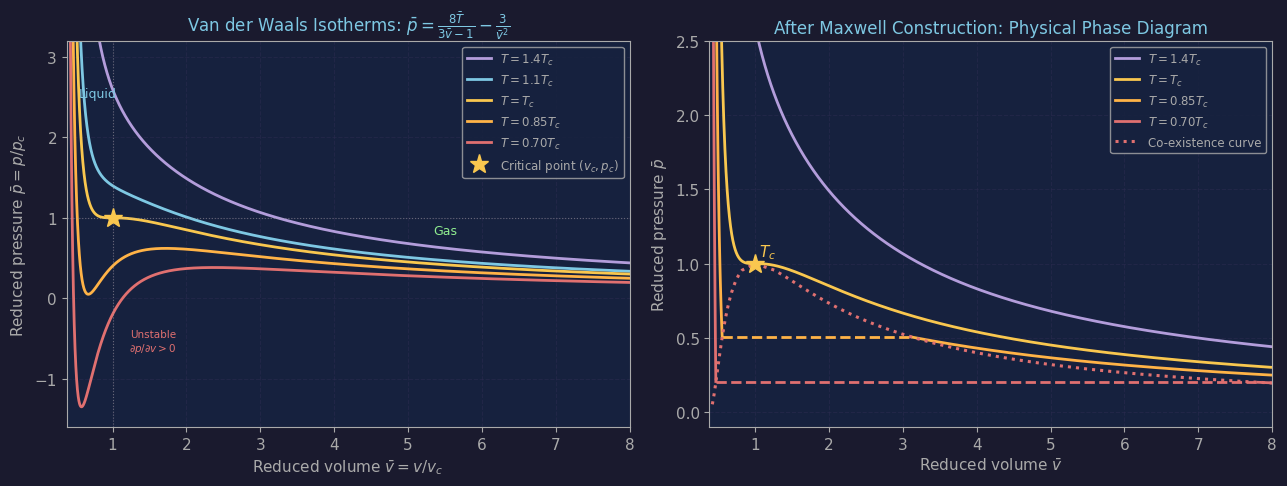

Saved.


In [2]:
base_style()

def vdw_p(v, T):
    """Van der Waals reduced pressure. v > 1/3 required."""
    return 8*T/(3*v - 1) - 3/v**2

def maxwell_peq_exact(T):
    """Find equilibrium pressure for T < Tc by solving equal-area rule with brentq.
    Returns (p_eq, v_liq, v_gas) or (None, None, None).
    """
    from scipy.optimize import brentq
    if T >= 1.0:
        return None, None, None

    def three_roots(p_try):
        """Return (v_liq, v_mid, v_gas) or None if fewer than 3 real roots."""
        # VdW rearranged: 3p*v^3 - (p+8T)*v^2 + 9v - 3 = 0
        coeffs = [3*p_try, -(p_try + 8*T), 9, -3]
        roots = np.roots(coeffs)
        real_roots = sorted([r.real for r in roots
                             if abs(r.imag) < 1e-9 and r.real > 1/3 + 1e-6])
        if len(real_roots) < 3:
            return None
        return real_roots[0], real_roots[1], real_roots[2]

    def area_diff(p_try):
        """Integral p dv from v_liq to v_gas minus p_eq*(v_gas - v_liq).
        Zero when Maxwell equal-area condition is satisfied.
        """
        roots = three_roots(p_try)
        if roots is None:
            return None
        v1, _, v3 = roots
        vv = np.linspace(v1, v3, 2000)
        pp = vdw_p(vv, T)
        return np.trapezoid(pp, vv) - p_try*(v3 - v1)

    # Find pressure bracket where area_diff changes sign
    # p must be between p_min (local min) and p_max (local max) of isotherm
    # Scan to find bracket
    p_lo, p_hi = None, None
    p_scan = np.linspace(0.05, 0.999, 500)
    vals = []
    for p0 in p_scan:
        d = area_diff(p0)
        if d is not None:
            vals.append((p0, d))

    for i in range(len(vals)-1):
        if vals[i][1] * vals[i+1][1] < 0:
            p_lo, p_hi = vals[i][0], vals[i+1][0]
            break

    if p_lo is None:
        return None, None, None

    p_eq = brentq(area_diff, p_lo, p_hi, xtol=1e-10, rtol=1e-10)
    roots = three_roots(p_eq)
    if roots is None:
        return None, None, None
    v_liq, _, v_gas = roots
    return p_eq, v_liq, v_gas

# ──────────────────────────────────────────────
# Figure
# ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5.0))

# ── Left: raw isotherms ────────────────────────
ax = axes[0]
v_left = np.linspace(1/3 + 0.005, 8.0, 5000)

temps      = [1.4, 1.1, 1.0, 0.85, 0.70]
colors_T   = [PURPLE, BLUE, YELLOW, ORANGE, RED]
labels_T   = [r'$T=1.4T_c$', r'$T=1.1T_c$', r'$T=T_c$', r'$T=0.85T_c$', r'$T=0.70T_c$']

for T, col, lbl in zip(temps, colors_T, labels_T):
    p = vdw_p(v_left, T)
    # Lower bound -1.6 so that T=0.70 negative-pressure unstable branch is visible
    mask = (p > -1.6) & (p < 3.5)
    ax.plot(v_left[mask], p[mask], color=col, linewidth=2.0, label=lbl)

ax.plot(1.0, 1.0, '*', color=YELLOW, markersize=14, zorder=5,
        label=r'Critical point $(v_c, p_c)$')
ax.axhline(1.0, color=DIM, linewidth=0.8, linestyle=':', alpha=0.5)
ax.axvline(1.0, color=DIM, linewidth=0.8, linestyle=':', alpha=0.5)

ax.set_xlabel(r'Reduced volume $\bar{v} = v/v_c$')
ax.set_ylabel(r'Reduced pressure $\bar{p} = p/p_c$')
ax.set_title(r'Van der Waals Isotherms: $\bar{p} = \frac{8\bar{T}}{3\bar{v}-1} - \frac{3}{\bar{v}^2}$')
ax.set_xlim(0.38, 8.0)
ax.set_ylim(-1.6, 3.2)
ax.legend(fontsize=8.5, loc='upper right')
ax.grid(True)

ax.text(0.8, 2.5,  'Liquid', color=BLUE,  fontsize=9, ha='center')
ax.text(5.5,  0.8, 'Gas', color=GREEN, fontsize=9, ha='center')
ax.text(1.55, -0.65, 'Unstable\n$\\partial p/\\partial v > 0$',
        color=RED, fontsize=7.5, ha='center')

# ── Right: after Maxwell construction ──────────
ax = axes[1]
v_right = np.linspace(1/3 + 0.005, 8.0, 5000)

# Compute exact co-existence curve
T_coex_arr = np.linspace(0.50, 0.999, 50)
v_liq_arr, v_gas_arr, p_eq_arr = [], [], []
for Tc_ in T_coex_arr:
    p_eq, vl, vg = maxwell_peq_exact(Tc_)
    if p_eq is not None:
        v_liq_arr.append(vl)
        v_gas_arr.append(vg)
        p_eq_arr.append(p_eq)

v_liq_arr = np.array(v_liq_arr)
v_gas_arr = np.array(v_gas_arr)
p_eq_arr  = np.array(p_eq_arr)

# Plot corrected isotherms
for T, col, lbl in zip([1.4, 1.0, 0.85, 0.70],
                        [PURPLE, YELLOW, ORANGE, RED],
                        [r'$T=1.4T_c$', r'$T=T_c$', r'$T=0.85T_c$', r'$T=0.70T_c$']):
    p_full = vdw_p(v_right, T)
    if T < 1.0:
        p_eq, vl, vg = maxwell_peq_exact(T)
        if p_eq is not None:
            mask_liq = (v_right < vl)  & (p_full > -0.3) & (p_full < 3.5)
            mask_gas = (v_right > vg)  & (p_full > -0.3) & (p_full < 3.5)
            ax.plot(v_right[mask_liq], p_full[mask_liq], color=col, linewidth=2.0)
            ax.plot([vl, vg], [p_eq, p_eq], color=col, linewidth=2.0, linestyle='--')
            ax.plot(v_right[mask_gas], p_full[mask_gas], color=col, linewidth=2.0, label=lbl)
        else:
            mask = (p_full > -0.3) & (p_full < 3.5)
            ax.plot(v_right[mask], p_full[mask], color=col, linewidth=2.0, label=lbl)
    else:
        mask = (p_full > -0.3) & (p_full < 3.5)
        ax.plot(v_right[mask], p_full[mask], color=col, linewidth=2.0, label=lbl)

# Co-existence curve — full extent to v_gas
v_coex_plot = np.concatenate([v_liq_arr, [1.0], v_gas_arr[::-1]])
p_coex_plot = np.concatenate([p_eq_arr,  [1.0], p_eq_arr[::-1]])
ax.plot(v_coex_plot, p_coex_plot,
        color=RED, linewidth=2.2, linestyle=':', label='Co-existence curve')

ax.plot(1.0, 1.0, '*', color=YELLOW, markersize=14, zorder=5)
ax.text(1.05, 1.05, r'$T_c$', color=YELLOW, fontsize=11)

ax.set_xlabel(r'Reduced volume $\bar{v}$')
ax.set_ylabel(r'Reduced pressure $\bar{p}$')
ax.set_title('After Maxwell Construction: Physical Phase Diagram')
ax.set_xlim(0.38, 8.0)
ax.set_ylim(-0.1, 2.5)
ax.legend(fontsize=8.5, loc='upper right')
ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_vdw_isotherms.png')
plt.show(); print('Saved.')


## Fig 2 — Maxwell Construction

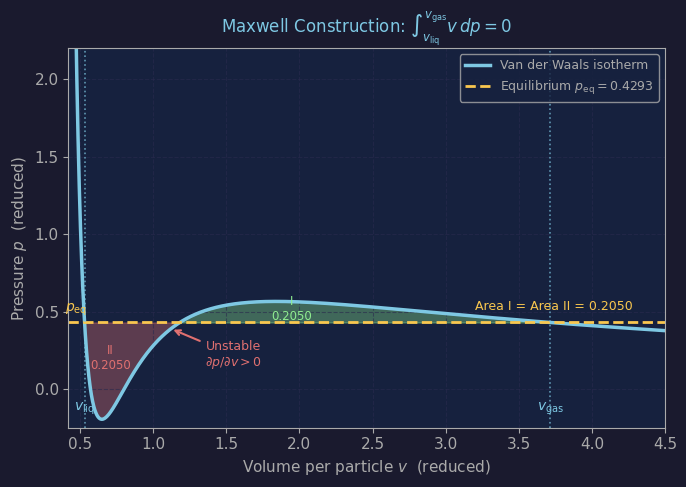

Saved.


In [3]:
base_style()

fig, ax = plt.subplots(figsize=(7, 5))

T = 0.82
v = np.linspace(1/3 + 0.005, 5.5, 5000)
p_curve = vdw_p(v, T)

# Exact Maxwell construction via brentq (defined in Cell 3)
p_eq, vl, vg = maxwell_peq_exact(T)

mask_show = (p_curve > -0.2) & (p_curve < 2.5) & (v < 5.0)
ax.plot(v[mask_show], p_curve[mask_show], color=BLUE, linewidth=2.5,
        label='Van der Waals isotherm')

if p_eq is not None:
    ax.axhline(p_eq, color=YELLOW, linewidth=2.0, linestyle='--',
               label=f'Equilibrium $p_{{\\rm eq}} = {p_eq:.4f}$')

    # ── Shaded areas ────────────────────────────────────────
    v_mid = v[(v >= vl) & (v <= vg)]
    p_mid = vdw_p(v_mid, T)

    # Area I (green): isotherm above p_eq  (left of local max)
    mask_upper = p_mid > p_eq
    v_up, p_up = v_mid[mask_upper], p_mid[mask_upper]
    area_I = np.trapezoid(np.maximum(p_up - p_eq, 0), v_up)
    if len(v_up) > 1:
        ax.fill_between(v_up, p_eq, p_up, alpha=0.35, color=GREEN)

    # Area II (red): isotherm below p_eq (right of local max)
    mask_lower = p_mid < p_eq
    v_lo, p_lo = v_mid[mask_lower], p_mid[mask_lower]
    area_II = np.trapezoid(np.maximum(p_eq - p_lo, 0), v_lo)
    if len(v_lo) > 1:
        ax.fill_between(v_lo, p_lo, p_eq, alpha=0.35, color=RED)

    # ── Labels ──────────────────────────────────────────────
    ax.axvline(vl, color=BLUE, linewidth=1.2, linestyle=':', alpha=0.7)
    ax.axvline(vg, color=BLUE, linewidth=1.2, linestyle=':', alpha=0.7)
    ax.text(vl,      -0.14, r'$v_{\rm liq}$', color=BLUE,   fontsize=10, ha='center')
    ax.text(vg,      -0.14, r'$v_{\rm gas}$', color=BLUE,   fontsize=10, ha='center')
    ax.text(0.40,  p_eq + 0.03, r'$p_{\rm eq}$',
            color=YELLOW, fontsize=10, va='bottom')

    # Area labels with computed values
    if len(v_up) > 1:
        vc_up = v_up[len(v_up)//2]
        ax.text(vc_up -0.5, p_eq +(p_up.max()-p_eq)*0.5 +0.02,
                f'I\n{area_I:.4f}', color=GREEN, fontsize=8.5, ha='center', va='center')
    if len(v_lo) > 1:
        vc_lo = v_lo[len(v_lo)//2]
        ax.text(vc_lo-0.15, p_eq - (p_eq - p_lo.min())*0.5 +0.08,
                f'II\n{area_II:.4f}', color=RED, fontsize=8.5, ha='center', va='center')

    ax.text(3.2, p_eq + 0.08,
            f'Area I = Area II = {area_I:.4f}',
            color=YELLOW, fontsize=9)

    # Unstable region
    ax.annotate('Unstable\n$\\partial p/\\partial v > 0$',
                xy=(1.12, p_eq - 0.04), xytext=(1.55, 0.15),
                arrowprops=dict(arrowstyle='->', color=RED, lw=1.5),
                color=RED, fontsize=9, ha='center')

ax.set_xlabel(r'Volume per particle $v$  (reduced)')
ax.set_ylabel(r'Pressure $p$  (reduced)')
ax.set_title(r'Maxwell Construction: $\int_{v_{\rm liq}}^{v_{\rm gas}} v\,dp = 0$')
ax.set_xlim(0.42, 4.5)
ax.set_ylim(-0.25, 2.2)
ax.legend(fontsize=9, loc='upper right')
ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_maxwell_construction.png')
plt.show(); print('Saved.')


## Fig 3 — Mean Field Theory: Graphical Solution

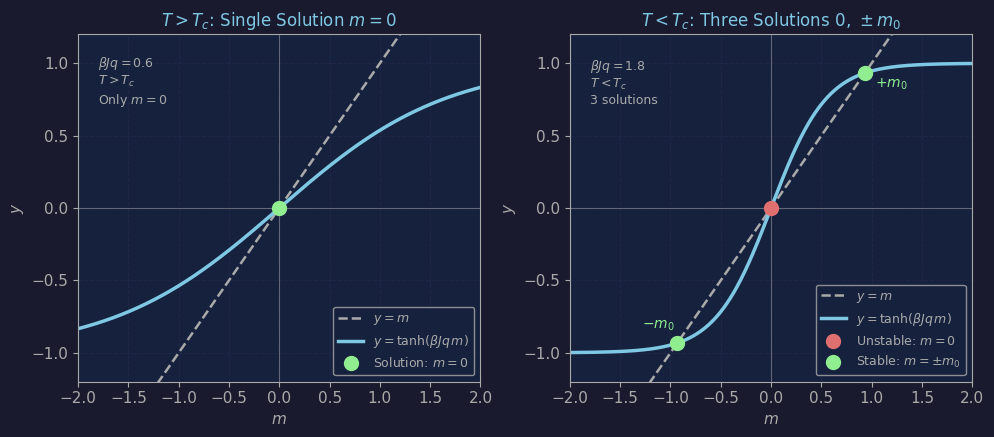

Saved.


In [4]:
base_style()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

m_arr = np.linspace(-2.0, 2.0, 500)

# Left: beta*J*q < 1  (T > Tc)
ax = axes[0]
beta_Jq = 0.6
tanh_vals = np.tanh(beta_Jq * m_arr)

ax.plot(m_arr, m_arr, color=DIM, linewidth=1.8, linestyle='--', label=r'$y = m$')
ax.plot(m_arr, tanh_vals, color=BLUE, linewidth=2.5, label=r'$y = \tanh(\beta Jq\,m)$')
ax.plot(0, 0, 'o', color=GREEN, markersize=10, zorder=5, label='Solution: $m=0$')

ax.axhline(0, color=DIM, linewidth=0.8, alpha=0.5)
ax.axvline(0, color=DIM, linewidth=0.8, alpha=0.5)
ax.text(0.05, 0.80, f'$\\beta Jq = {beta_Jq}$\n$T > T_c$\nOnly $m=0$',
        transform=ax.transAxes, color=DIM, fontsize=9)

ax.set_xlabel(r'$m$')
ax.set_ylabel(r'$y$')
ax.set_title(r'$T > T_c$: Single Solution $m = 0$')
ax.set_xlim(-2, 2); ax.set_ylim(-1.2, 1.2)
ax.legend(fontsize=9); ax.grid(True)

# Right: beta*J*q > 1  (T < Tc)
ax = axes[1]
beta_Jq = 1.8
tanh_vals = np.tanh(beta_Jq * m_arr)

ax.plot(m_arr, m_arr, color=DIM, linewidth=1.8, linestyle='--', label=r'$y = m$')
ax.plot(m_arr, tanh_vals, color=BLUE, linewidth=2.5, label=r'$y = \tanh(\beta Jq\,m)$')

# Find intersections
from scipy.optimize import brentq
f = lambda m: np.tanh(beta_Jq * m) - m
m0 = brentq(f, 0.1, 1.5)
ax.plot(0, 0, 'o', color=RED, markersize=10, zorder=5, label='Unstable: $m=0$')
ax.plot(m0, m0, 'o', color=GREEN, markersize=10, zorder=5)
ax.plot(-m0, -m0, 'o', color=GREEN, markersize=10, zorder=5, label=r'Stable: $m = \pm m_0$')

ax.axhline(0, color=DIM, linewidth=0.8, alpha=0.5)
ax.axvline(0, color=DIM, linewidth=0.8, alpha=0.5)
ax.annotate(r'$+m_0$', xy=(m0, m0), xytext=(m0+0.1, m0-0.1), color=GREEN, fontsize=10)
ax.annotate(r'$-m_0$', xy=(-m0, -m0), xytext=(-m0-0.35, -m0+0.1), color=GREEN, fontsize=10)
ax.text(0.05, 0.80, f'$\\beta Jq = {beta_Jq}$\n$T < T_c$\n3 solutions',
        transform=ax.transAxes, color=DIM, fontsize=9)

ax.set_xlabel(r'$m$')
ax.set_ylabel(r'$y$')
ax.set_title(r'$T < T_c$: Three Solutions $0,\, \pm m_0$')
ax.set_xlim(-2, 2); ax.set_ylim(-1.2, 1.2)
ax.legend(fontsize=9); ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_mft_selfconsistency.png')
plt.show(); print('Saved.')


## Fig 4 — Mean Field Magnetisation m(T)

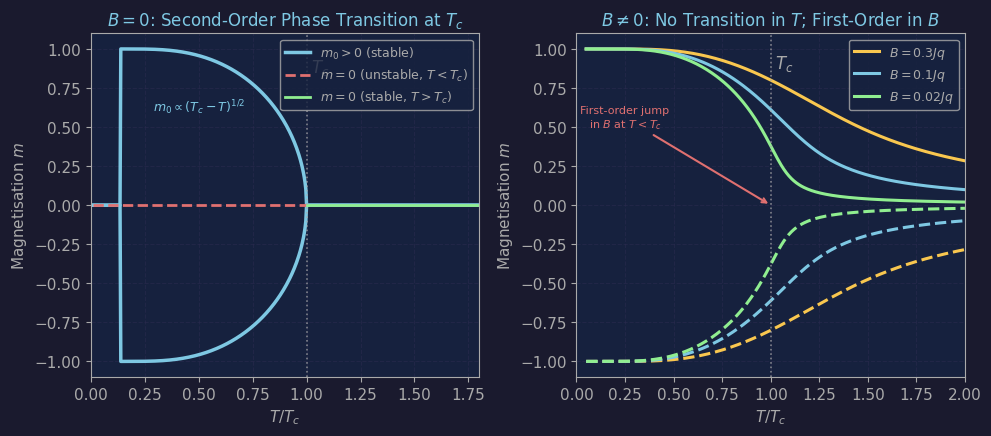

Saved.


In [5]:
base_style()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))

# Solve m = tanh(beta*Jq*m) numerically
from scipy.optimize import brentq

def get_m0(T_over_Tc):
    beta_Jq = 1.0 / T_over_Tc
    f = lambda m: np.tanh(beta_Jq * m) - m
    if beta_Jq <= 1:
        return 0.0
    try:
        return brentq(f, 1e-6, 1.0 - 1e-6)
    except:
        return 0.0

T_arr = np.linspace(0.01, 1.8, 500)
m0_arr = np.array([get_m0(T) for T in T_arr])

# Left: B = 0
ax = axes[0]
ax.plot(T_arr, m0_arr,  color=BLUE,   linewidth=2.5, label='$m_0 > 0$ (stable)')
ax.plot(T_arr, -m0_arr, color=BLUE,   linewidth=2.5)
ax.plot(T_arr[T_arr < 1.0], np.zeros(sum(T_arr < 1.0)), color=RED,
        linewidth=2.0, linestyle='--', label='$m=0$ (unstable, $T<T_c$)')
ax.plot(T_arr[T_arr >= 1.0], np.zeros(sum(T_arr >= 1.0)), color=GREEN,
        linewidth=2.0, label='$m=0$ (stable, $T>T_c$)')

ax.axvline(1.0, color=DIM, linewidth=1.2, linestyle=':', alpha=0.7)
ax.text(1.02, 0.85, r'$T_c$', color=DIM, fontsize=12)
ax.text(0.5, 0.6, r'$m_0 \propto (T_c-T)^{1/2}$', color=BLUE, fontsize=9, ha='center')

ax.set_xlabel(r'$T / T_c$')
ax.set_ylabel(r'Magnetisation $m$')
ax.set_title(r'$B=0$: Second-Order Phase Transition at $T_c$')
ax.set_xlim(0, 1.8); ax.set_ylim(-1.1, 1.1)
ax.legend(fontsize=9, loc='upper right'); ax.grid(True)

# Right: B != 0 (no phase transition in T, but first-order in B)
ax = axes[1]

def get_m_Bfield(T_over_Tc, B_over_Jq):
    """Solve m = tanh(beta*(B + Jq*m)) for given T and B."""
    beta_Jq = 1.0 / T_over_Tc
    f = lambda m: np.tanh(beta_Jq * (B_over_Jq + m)) - m
    # Find the physical (stable) root
    try:
        # Start from the sign of B
        sign = 1 if B_over_Jq >= 0 else -1
        return brentq(f, sign*1e-6, sign*1.0, maxiter=200)
    except:
        # Fallback: scan
        vals = np.linspace(-1.0, 1.0, 200)
        fvals = [abs(f(m)) for m in vals]
        return vals[np.argmin(fvals)]

T_arr2 = np.linspace(0.05, 2.0, 300)
B_values = [0.3, 0.1, 0.02]
colors_B = [YELLOW, BLUE, GREEN]
labels_B = [r'$B = 0.3 Jq$', r'$B = 0.1 Jq$', r'$B = 0.02 Jq$']

for B, col, lbl in zip(B_values, colors_B, labels_B):
    m_pos = np.array([get_m_Bfield(T, B) for T in T_arr2])
    m_neg = np.array([get_m_Bfield(T, -B) for T in T_arr2])
    ax.plot(T_arr2, m_pos, color=col, linewidth=2.2, label=lbl)
    ax.plot(T_arr2, m_neg, color=col, linewidth=2.2, linestyle='--')

ax.axvline(1.0, color=DIM, linewidth=1.2, linestyle=':', alpha=0.7)
ax.text(1.02, 0.88, r'$T_c$', color=DIM, fontsize=12)
ax.annotate('First-order jump\nin $B$ at $T<T_c$',
            xy=(1.0, 0.0), xytext=(0.25, 0.5),
            arrowprops=dict(arrowstyle='->', color=RED, lw=1.5),
            color=RED, fontsize=8, ha='center')

ax.set_xlabel(r'$T / T_c$')
ax.set_ylabel(r'Magnetisation $m$')
ax.set_title(r'$B \neq 0$: No Transition in $T$; First-Order in $B$')
ax.set_xlim(0, 2.0); ax.set_ylim(-1.1, 1.1)
ax.legend(fontsize=9, loc='upper right'); ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_mft_magnetisation.png')
plt.show(); print('Saved.')


## Fig 5 — Landau Theory: Second Order Transition

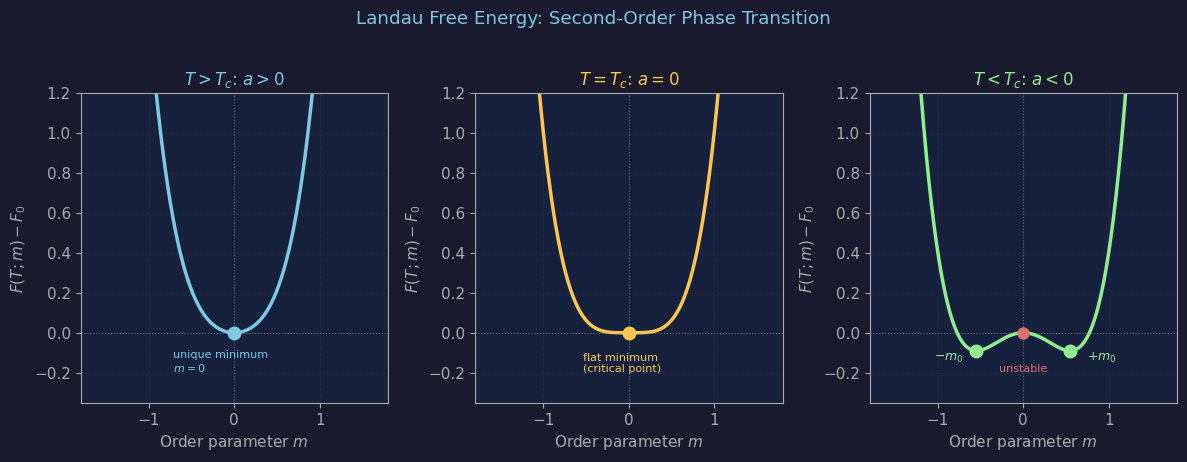

Saved.


In [6]:
base_style()

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

m = np.linspace(-1.8, 1.8, 500)
b = 1.0

temps = [
    (0.6, r'$T > T_c$: $a > 0$', BLUE),
    (0.0, r'$T = T_c$: $a = 0$', YELLOW),
    (-0.6, r'$T < T_c$: $a < 0$', GREEN),
]

for ax, (a, title, col) in zip(axes, temps):
    F = a * m**2 + b * m**4
    ax.plot(m, F, color=col, linewidth=2.5)
    ax.axhline(0, color=DIM, linewidth=0.8, linestyle=':', alpha=0.5)
    ax.axvline(0, color=DIM, linewidth=0.8, linestyle=':', alpha=0.5)

    if a < 0:
        m0 = np.sqrt(-a / (2*b))
        F0 = a * m0**2 + b * m0**4
        ax.plot([ m0, -m0], [F0, F0], 'o', color=GREEN, markersize=9, zorder=5)
        ax.annotate(r'$+m_0$', xy=(m0, F0), xytext=(m0+0.2, F0-0.05), color=GREEN, fontsize=9)
        ax.annotate(r'$-m_0$', xy=(-m0, F0), xytext=(-m0-0.5, F0-0.05), color=GREEN, fontsize=9)
        ax.plot(0, 0, 'o', color=RED, markersize=8, zorder=5)
        ax.text(0.42, 0.1, 'unstable', color=RED, fontsize=8, transform=ax.transAxes)
    elif a == 0:
        ax.plot(0, 0, 'o', color=YELLOW, markersize=9, zorder=5)
        ax.text(0.35, 0.1, 'flat minimum\n(critical point)', color=YELLOW, fontsize=8, transform=ax.transAxes)
    else:
        ax.plot(0, 0, 'o', color=BLUE, markersize=9, zorder=5)
        ax.text(0.3, 0.1, 'unique minimum\n$m=0$', color=BLUE, fontsize=8, transform=ax.transAxes)

    ax.set_xlabel(r'Order parameter $m$')
    ax.set_ylabel(r'$F(T;m) - F_0$')
    ax.set_title(title, color=col)
    ax.set_xlim(-1.8, 1.8)
    ax.set_ylim(-0.35, 1.2)
    ax.grid(True)

fig.suptitle(r'Landau Free Energy: Second-Order Phase Transition', color=BLUE, y=1.02)
fig.tight_layout()
fig.savefig('figures/fig_landau_second_order.png', bbox_inches='tight')
plt.show(); print('Saved.')


## Fig 6 — Landau Theory: First Order Transition

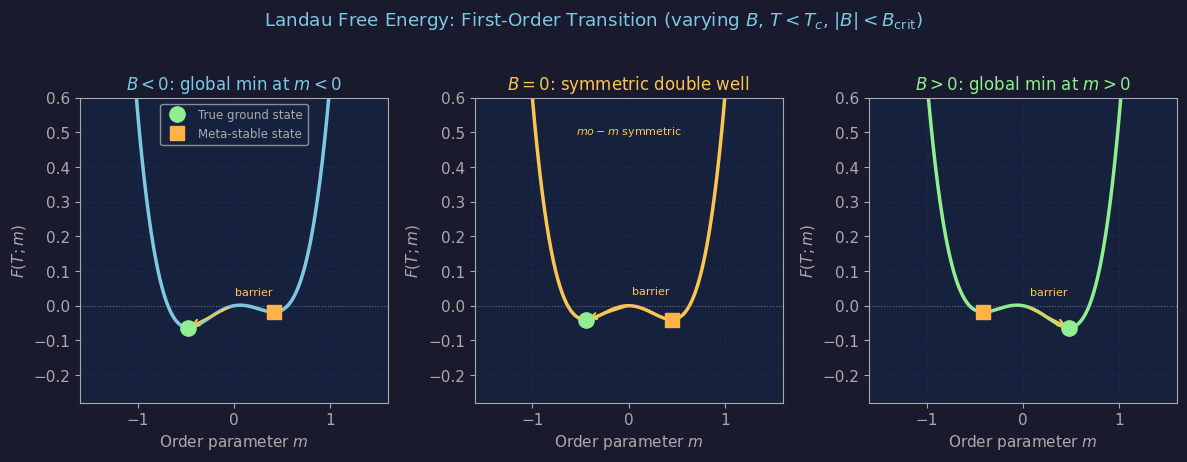

Saved.


In [7]:
base_style()

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

m = np.linspace(-1.6, 1.6, 800)
a, b = -0.4, 1.0   # T < Tc

# B must satisfy |B| < B_crit ≈ 0.138 for the double-well to exist.
# B = 0.05 is well inside this range → both wells are present.
B_vals  = [-0.05, 0.0, 0.05]
titles  = [r'$B < 0$: global min at $m < 0$',
           r'$B = 0$: symmetric double well',
           r'$B > 0$: global min at $m > 0$']
colors_B2 = [BLUE, YELLOW, GREEN]

for ax, B, title, col in zip(axes, B_vals, titles, colors_B2):
    F = -B*m + a*m**2 + b*m**4

    ax.plot(m, F, color=col, linewidth=2.5)
    ax.axhline(0, color=DIM, linewidth=0.8, linestyle=':', alpha=0.5)

    # Find local minima analytically: dF/dm = -B + 2a*m + 4b*m^3 = 0
    coeffs = [4*b, 0, 2*a, -B]   # 4b*m^3 + 2a*m - B = 0
    roots  = np.roots(coeffs)
    min_ms = sorted([r.real for r in roots if abs(r.imag) < 1e-8])

    # Classify: local min if d²F/dm² = 2a + 12b*m² > 0
    minima = [(m_, -B*m_ + a*m_**2 + b*m_**4)
              for m_ in min_ms if 2*a + 12*b*m_**2 > 0]

    if len(minima) == 2:
        F_vals   = [mi[1] for mi in minima]
        true_idx = int(np.argmin(F_vals))
        meta_idx = 1 - true_idx
        ax.plot(*minima[true_idx], 'o', color=GREEN,  markersize=11, zorder=6,
                label='True ground state')
        ax.plot(*minima[meta_idx], 's', color=ORANGE, markersize=10, zorder=6,
                label='Meta-stable state')
        # Energy barrier arrow
        m_bar = (minima[0][0] + minima[1][0]) / 2
        F_bar = -B*m_bar + a*m_bar**2 + b*m_bar**4
        ax.annotate('', xy=minima[true_idx], xytext=(m_bar, F_bar),
                    arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.5))
        ax.text(m_bar + 0.04, F_bar +0.04, 'barrier', color=YELLOW, fontsize=8, va='center')
    elif len(minima) == 1:
        ax.plot(*minima[0], 'o', color=GREEN, markersize=11, zorder=6)

    if B == 0:
        ax.text(0.5, 0.88, r'$m \to -m$ symmetric',
                transform=ax.transAxes, color=YELLOW, fontsize=8, ha='center')

    ax.set_xlabel(r'Order parameter $m$')
    ax.set_ylabel(r'$F(T;m)$')
    ax.set_title(title, color=col)
    ax.set_xlim(-1.6, 1.6)
    ax.set_ylim(-0.28, 0.6)
    ax.grid(True)

axes[0].legend(fontsize=8.5, loc='upper center')
fig.suptitle(
    r'Landau Free Energy: First-Order Transition (varying $B$, $T < T_c$, $|B| < B_{\rm crit}$)',
    color=BLUE, y=1.02)
fig.tight_layout()
fig.savefig('figures/fig_landau_first_order.png', bbox_inches='tight')
plt.show(); print('Saved.')


## Fig 7 — Lee-Yang Zeros in the Complex z-Plane

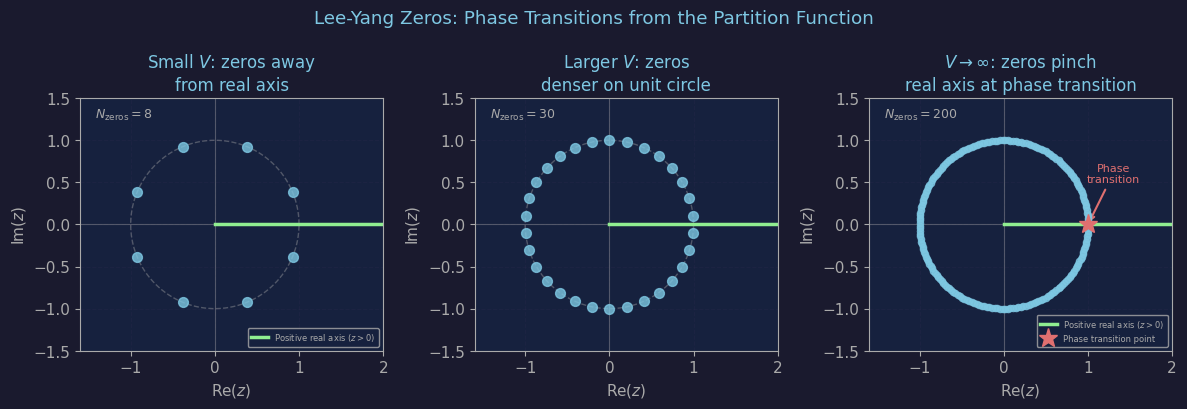

Saved.


In [8]:
base_style()

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

titles = ['Small $V$: zeros away\nfrom real axis',
          'Larger $V$: zeros\ndenser on unit circle',
          '$V\\to\\infty$: zeros pinch\nreal axis at phase transition']

N_zeros_list = [8, 30, 200]

for ax, (N_z, title) in zip(axes, zip(N_zeros_list, titles)):
    ax.set_aspect('equal')
    theta = np.linspace(0, 2*np.pi, 500)
    ax.plot(np.cos(theta), np.sin(theta), color=DIM, linewidth=1.0, linestyle='--', alpha=0.4)

    # Zeros on unit circle (excluding positive real)
    n_arr = np.arange(N_z)
    angles = np.pi * (2*n_arr + 1) / N_z  # avoid angle=0 (positive real)
    zx = np.cos(angles)
    zy = np.sin(angles)

    ax.scatter(zx, zy, color=BLUE, s=20 if N_z > 50 else 50, zorder=5, alpha=0.8)

    # Positive real axis
    ax.axhline(0, color=DIM, linewidth=0.8, alpha=0.4)
    ax.axvline(0, color=DIM, linewidth=0.8, alpha=0.4)
    ax.plot([0, 2], [0, 0], color=GREEN, linewidth=2.5, label='Positive real axis ($z>0$)')

    if N_z > 100:
        # Show pinching point
        ax.plot(1.0, 0, '*', color=RED, markersize=14, zorder=6,
                label='Phase transition point')
        ax.annotate('Phase\ntransition', xy=(1.0, 0.0), xytext=(1.3, 0.5),
                    arrowprops=dict(arrowstyle='->', color=RED, lw=1.5),
                    color=RED, fontsize=8, ha='center')

    ax.text(0.05, 0.92, f'$N_{{\\rm zeros}} = {N_z}$',
            transform=ax.transAxes, color=DIM, fontsize=9)
    ax.set_xlim(-1.6, 2.0); ax.set_ylim(-1.5, 1.5)
    ax.set_xlabel(r'Re$(z)$'); ax.set_ylabel(r'Im$(z)$')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

axes[0].legend(fontsize=6, loc='lower right')
axes[2].legend(fontsize=6, loc='lower right')
fig.suptitle('Lee-Yang Zeros: Phase Transitions from the Partition Function', color=BLUE, y=0.94)
fig.tight_layout()
fig.savefig('figures/fig_lee_yang.png', bbox_inches='tight')
plt.show(); print('Saved.')


## Fig 8 — Domain Wall Profile

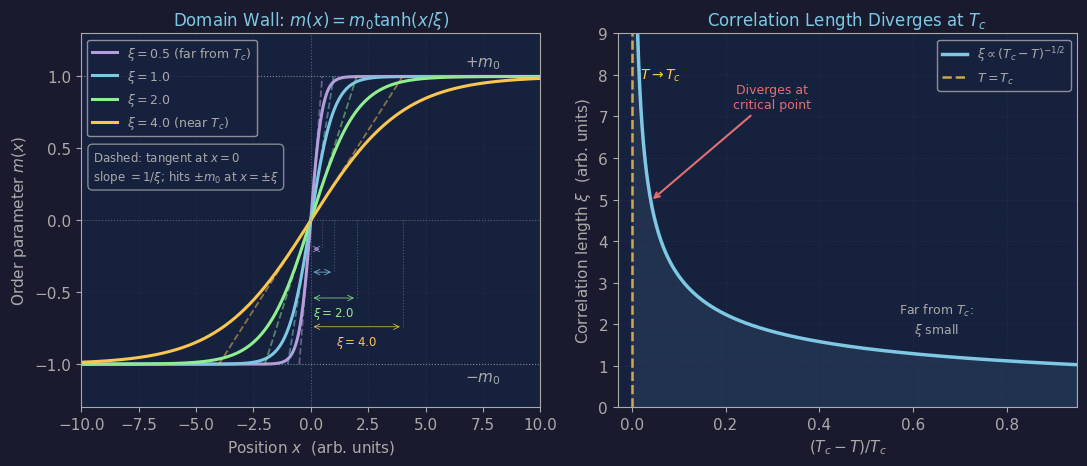

Saved.


In [9]:
base_style()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

# ── Left: domain wall profiles ────────────────────────────────────────────────
ax = axes[0]
x = np.linspace(-10, 10, 1000)

xi_vals    = [0.5,  1.0,   2.0,   4.0]
colors_xi  = [PURPLE, BLUE, GREEN, YELLOW]
labels_xi  = [r'$\xi=0.5$ (far from $T_c$)', r'$\xi=1.0$',
              r'$\xi=2.0$', r'$\xi=4.0$ (near $T_c$)']

for xi, col, lbl in zip(xi_vals, colors_xi, labels_xi):
    ax.plot(x, np.tanh(x / xi), color=col, linewidth=2.2, label=lbl)

ax.axhline( 1.0, color=DIM, linewidth=0.8, linestyle=':', alpha=0.7)
ax.axhline(-1.0, color=DIM, linewidth=0.8, linestyle=':', alpha=0.7)
ax.axhline( 0.0, color=DIM, linewidth=0.8, linestyle=':', alpha=0.4)
ax.axvline( 0.0, color=DIM, linewidth=0.8, linestyle=':', alpha=0.4)
ax.text( 7.5,  1.07, r'$+m_0$', color=DIM, fontsize=11, ha='center')
ax.text( 7.5, -1.12, r'$-m_0$', color=DIM, fontsize=11, ha='center')

# ── Dashed tangent lines at x=0 ───────────────────────────────────────────────
# tanh'(x/ξ)|_{x=0} = 1/ξ  →  tangent y = x/ξ  intersects y = ±1 at x = ±ξ
for xi, col in zip(xi_vals, colors_xi):
    ax.plot([-xi, xi], [-1.0, 1.0], color=col, lw=1.3, ls='--', alpha=0.50, zorder=2)

# ── Staggered width brackets (0 → +ξ) — one per row so they never overlap ─────
y_rows = [-0.20, -0.36, -0.54, -0.74]   # deeper row for each successive ξ
for xi, col, y_brk in zip(xi_vals, colors_xi, y_rows):
    # Faint vertical guide from x-axis down to bracket level
    ax.plot([xi, xi], [0.0, y_brk], color=col, lw=0.8, ls=':', alpha=0.35, zorder=2)
    # Horizontal double-headed arrow: 0 → +ξ
    ax.annotate('', xy=(xi, y_brk), xytext=(0.0, y_brk),
                arrowprops=dict(arrowstyle='<->', color=col, lw=0.5,
                                mutation_scale=10))

    if xi in [2.0, 4.0]:
      # ξ label at midpoint of bracket
      ax.text(xi / 2, y_brk - 0.05, fr'$\xi = {xi}$',
              color=col, fontsize=8.5, ha='center', va='top',
              bbox=dict(facecolor=PANEL_BG, edgecolor='none', pad=1.0, alpha=0.9))

# Explanation box
ax.text(-9.5, 0.37,
        'Dashed: tangent at $x=0$\n'
        r'slope $=1/\xi$; hits $\pm m_0$ at $x=\pm\xi$',
        color=DIM, fontsize=8.5, va='center',
        bbox=dict(facecolor=PANEL_BG, edgecolor=DIM, alpha=0.75,
                  boxstyle='round,pad=0.4'))

ax.set_xlabel(r'Position $x$  (arb. units)')
ax.set_ylabel(r'Order parameter $m(x)$')
ax.set_title(r'Domain Wall: $m(x) = m_0\tanh(x/\xi)$')
ax.set_xlim(-10, 10)
ax.set_ylim(-1.30, 1.30)
ax.legend(fontsize=9, loc='upper left')
ax.grid(True)

# ── Right: correlation length diverges ───────────────────────────────────────
ax = axes[1]

t = np.linspace(1e-4, 0.95, 400)   # (Tc-T)/Tc
xi_T = 1.0 / np.sqrt(t)

ax.plot(t, xi_T, color=BLUE, linewidth=2.5,
        label=r'$\xi \propto (T_c - T)^{-1/2}$')
ax.fill_between(t, 0, xi_T, alpha=0.10, color=BLUE)

ax.axvline(0.0, color=YELLOW, linewidth=1.8, linestyle='--', alpha=0.8,
           label=r'$T = T_c$')
ax.text(0.018, 8.2, r'$T \to T_c$', color=YELLOW, fontsize=10, va='top')

ax.text(0.65, 1.8, r'Far from $T_c$:' + '\n' + r'$\xi$ small',
        color=DIM, fontsize=9, ha='center')
ax.annotate('Diverges at\ncritical point',
            xy=(0.04, xi_T[np.searchsorted(t, 0.04)]),
            xytext=(0.30, 7.2),
            arrowprops=dict(arrowstyle='->', color=RED, lw=1.5),
            color=RED, fontsize=9, ha='center')

ax.set_xlabel(r'$(T_c - T)/T_c$')
ax.set_ylabel(r'Correlation length $\xi$  (arb. units)')
ax.set_title(r'Correlation Length Diverges at $T_c$')
ax.set_xlim(-0.03, 0.95)
ax.set_ylim(0, 9)
ax.legend(fontsize=9)
ax.grid(True)

fig.tight_layout()
fig.savefig('figures/fig_domain_wall.png')
plt.show(); print('Saved.')


## Summary

All figures saved to `./figures/`.

Copy the `figures/` folder next to `statphys_ch05_slides.qmd` and render:
```bash
quarto render statphys_ch05_slides.qmd
```


In [10]:
# ── Download all figures as a zip file (Colab) ───────────────────────────────
import zipfile, os

zip_path = 'statphys_ch05_figures.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir('figures')):
        if fname.endswith('.png'):
            fpath = os.path.join('figures', fname)
            zf.write(fpath, fname)
            print(f'  Added: {fname}')

print(f'\nZip created: {zip_path}')
print(f'Size: {os.path.getsize(zip_path) / 1024:.1f} KB')

try:
    from google.colab import files
    files.download(zip_path)
    print('Download started!')
except ImportError:
    print(f'Not in Colab — file saved locally as: {zip_path}')


  Added: fig_domain_wall.png
  Added: fig_landau_first_order.png
  Added: fig_landau_second_order.png
  Added: fig_lee_yang.png
  Added: fig_maxwell_construction.png
  Added: fig_mft_magnetisation.png
  Added: fig_mft_selfconsistency.png
  Added: fig_vdw_isotherms.png

Zip created: statphys_ch05_figures.zip
Size: 1105.1 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started!
